In [5]:
import sys
sys.path.append("../src")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from features import make_features
from backtest import run_backtest

df = pd.read_csv("../data/clean_hourly.csv", index_col=0, parse_dates=True)
df = make_features(df)

In [6]:
months = pd.date_range("2012-01-01", "2012-12-01", freq="MS")

results, preds = run_backtest(df, months)
results

done: 2012-01
done: 2012-02
done: 2012-03
done: 2012-04
done: 2012-05
done: 2012-06
done: 2012-07
done: 2012-08
done: 2012-09
done: 2012-10
done: 2012-11
done: 2012-12


,month,fit_rows,mae_median,coverage_raw,coverage_cal,width_raw,width_cal,correction
0,2012-01,6361,43.262892,0.866935,0.885753,148.707260,155.160939,3.451065
1,2012-02,7105,35.136332,0.875000,0.900862,150.530258,163.592355,7.045185
2,2012-03,7825,56.348705,0.809140,0.825269,179.393402,189.787622,5.496918
3,2012-04,8569,58.385534,0.768056,0.804167,195.293793,217.645088,11.974043
4,2012-05,9313,61.485417,0.774194,0.845430,202.934525,277.690795,41.982544
5,2012-06,10009,60.128904,0.780556,0.888889,212.665970,344.812912,75.175049
6,2012-07,10753,57.935047,0.858871,0.905914,247.243042,297.022102,26.934509
7,2012-08,11473,49.968440,0.873656,0.893817,224.963379,252.441510,14.561829
8,2012-09,12217,60.033916,0.815278,0.841667,235.414536,252.592139,8.976929
9,2012-10,12937,58.110346,0.803763,0.848118,235.849045,257.186866,11.299316


In [8]:
print("Average coverage (raw):       ", results["coverage_raw"].mean())
print("Average coverage (calibrated):", results["coverage_cal"].mean())
print("Worst month (raw):       ", results["coverage_raw"].min())
print("Worst month (calibrated):", results["coverage_cal"].min())
print("Std of coverage (raw):       ", results["coverage_raw"].std())
print("Std of coverage (calibrated):", results["coverage_cal"].std())
print("Average width (raw):       ", results["width_raw"].mean())
print("Average width (calibrated):", results["width_cal"].mean())

Average coverage (raw):        0.8300851254480287
Average coverage (calibrated): 0.8735410744448564
Worst month (raw):        0.7680555555555556
Worst month (calibrated): 0.8041666666666667
Std of coverage (raw):        0.04349544588153458
Std of coverage (calibrated): 0.03920035429465879
Average width (raw):        205.27321
Average width (calibrated): 241.2304623740915


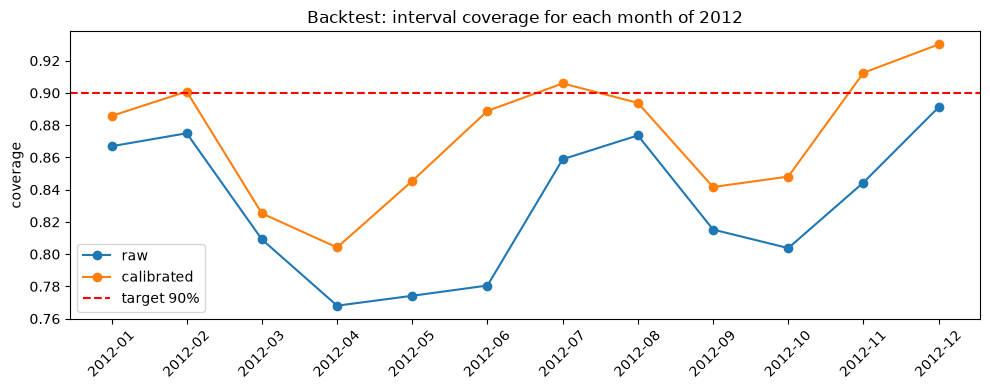

In [4]:
plt.figure(figsize=(10, 4))
plt.plot(results["month"], results["coverage_raw"], marker="o", label="raw")
plt.plot(results["month"], results["coverage_cal"], marker="o", label="calibrated")
plt.axhline(0.9, color="red", linestyle="--", label="target 90%")
plt.xticks(rotation=45)
plt.ylabel("coverage")
plt.title("Backtest: interval coverage for each month of 2012")
plt.legend()
plt.tight_layout()
plt.savefig("../results/backtest_coverage.png")
plt.show()

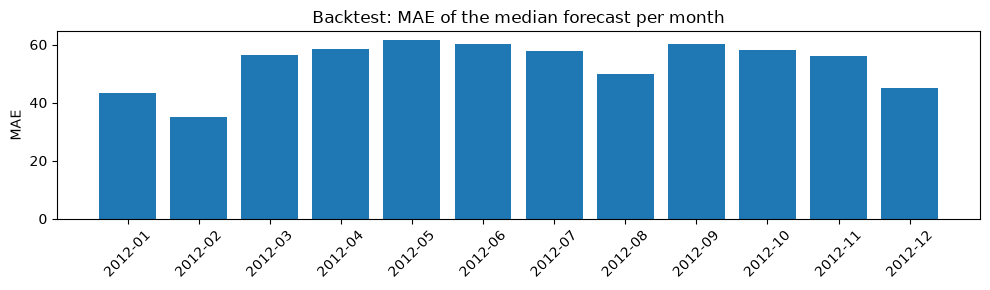

In [5]:
plt.figure(figsize=(10, 3))
plt.bar(results["month"], results["mae_median"])
plt.xticks(rotation=45)
plt.ylabel("MAE")
plt.title("Backtest: MAE of the median forecast per month")
plt.tight_layout()
plt.savefig("../results/backtest_mae.png")
plt.show()

In [6]:
results.to_csv("../results/backtest_results.csv", index=False)
preds.to_csv("../results/backtest_predictions.csv")